In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("student_data_100 (1).csv")

df.head()

,name,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,schoolsup,famsup,paid,activities,internet,romantic,absences,G1,G2,G3
0,Kabir,M,18,U,LE3,T,0,2,at_home,services,...,yes,no,yes,no,no,no,5,19,3,19
1,Tanvi,F,17,U,GT3,A,3,2,at_home,other,...,no,yes,no,yes,no,yes,15,14,0,18
2,Ananya,F,22,R,LE3,T,2,3,health,teacher,...,no,yes,yes,yes,no,no,2,10,18,2
3,Ashish,M,18,U,GT3,A,0,4,at_home,health,...,yes,no,no,no,yes,yes,5,2,17,9
4,Vrinda,F,20,U,GT3,T,0,1,health,at_home,...,no,no,no,no,yes,no,23,11,5,0


In [2]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Shape: (100, 21)

Columns:
['name', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'internet', 'romantic', 'absences', 'G1', 'G2', 'G3']

Data types:
name            str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
guardian        str
schoolsup       str
famsup          str
paid            str
activities      str
internet        str
romantic        str
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object

Missing values:
name          0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
guardian      0
schoolsup     0
famsup        0
paid          0
activities    0
internet      0
romantic      0
absences      0
G1            0
G2    

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,100.0,18.66,2.454516,15.0,16.0,19.0,21.0,22.0
Medu,100.0,1.74,1.467631,0.0,0.0,2.0,3.0,4.0
Fedu,100.0,2.06,1.427154,0.0,1.0,2.0,3.0,4.0
absences,100.0,14.54,8.463135,0.0,8.0,15.0,21.0,29.0
G1,100.0,9.21,6.618454,0.0,3.0,9.0,15.0,20.0
G2,100.0,9.96,5.789088,0.0,5.0,10.0,15.0,20.0
G3,100.0,9.92,6.422310,0.0,5.0,9.0,16.0,20.0


In [4]:
features = ["G1", "G2", "absences", "age", "Medu", "Fedu"]

X = df[features]
y = df["G3"]

print("Features:", features)
print("Target: G3")
print("X shape:", X.shape)
print("y shape:", y.shape)


Features: ['G1', 'G2', 'absences', 'age', 'Medu', 'Fedu']
Target: G3
X shape: (100, 6)
y shape: (100,)


G3          1.000000
age         0.166141
absences    0.029608
Fedu       -0.002777
G2         -0.104957
G1         -0.119846
Medu       -0.227278
Name: G3, dtype: float64


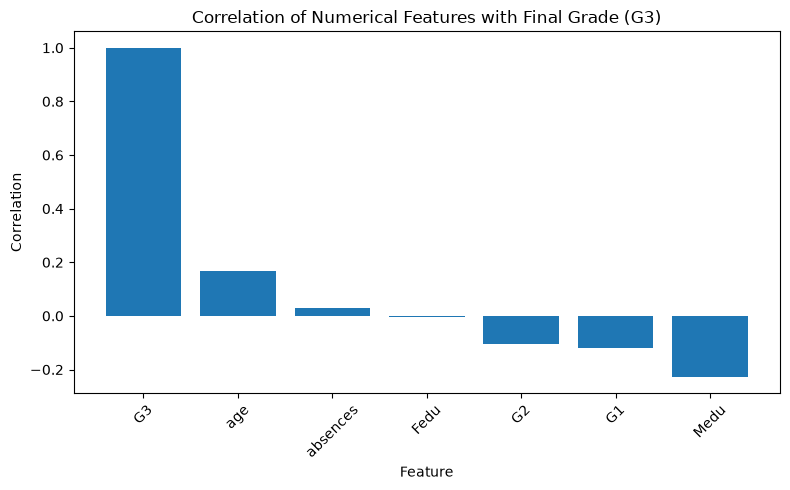

In [5]:
# Correlation with final score
correlations = df[features + ["G3"]].corr()["G3"].sort_values(ascending=False)
print(correlations)

plt.figure(figsize=(8,5))
plt.bar(correlations.index, correlations.values)
plt.title("Correlation of Numerical Features with Final Grade (G3)")
plt.xlabel("Feature")
plt.ylabel("Correlation")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


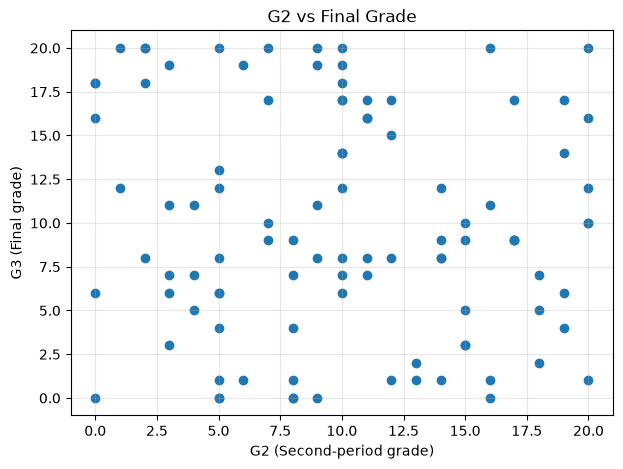

In [6]:
# Relationship between second-period grade and final grade
plt.figure(figsize=(7,5))
plt.scatter(df["G2"], df["G3"])
plt.xlabel("G2 (Second-period grade)")
plt.ylabel("G3 (Final grade)")
plt.title("G2 vs Final Grade")
plt.grid(True, alpha=0.3)
plt.show()


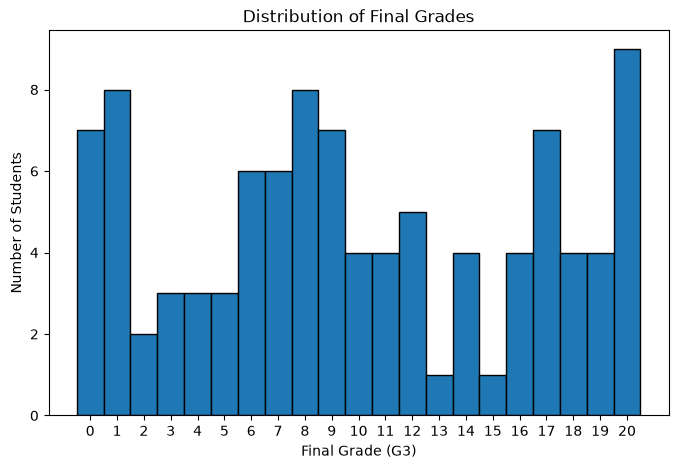

In [7]:
# Distribution of final scores
plt.figure(figsize=(8,5))
plt.hist(df["G3"], bins=range(0,22), edgecolor="black", align="left")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.title("Distribution of Final Grades")
plt.xticks(range(0,21))
plt.show()


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 80
Testing samples: 20


In [9]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 4))

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
}).sort_values("Coefficient", ascending=False)

coefficients


Intercept: 5.325


,Feature,Coefficient
3,age,0.497098
2,absences,0.066118
0,G1,-0.140969
5,Fedu,-0.150121
1,G2,-0.178170
4,Medu,-1.082851


In [10]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual G3": y_test.values,
    "Predicted G3": np.round(y_pred, 2)
})

results["Error"] = results["Actual G3"] - results["Predicted G3"]
results.head(10)


,Actual G3,Predicted G3,Error
0,7,9.45,-2.45
1,0,8.59,-8.59
2,19,13.24,5.76
3,4,14.09,-10.09
4,5,10.23,-5.23
5,1,6.90,-5.90
6,10,7.07,2.93
7,8,12.39,-4.39
8,9,9.80,-0.80
9,19,11.09,7.91


In [11]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.3f}")
print(f"MSE  : {mse:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.3f}")


MAE  : 4.778
MSE  : 34.209
RMSE : 5.849
R²   : 0.006


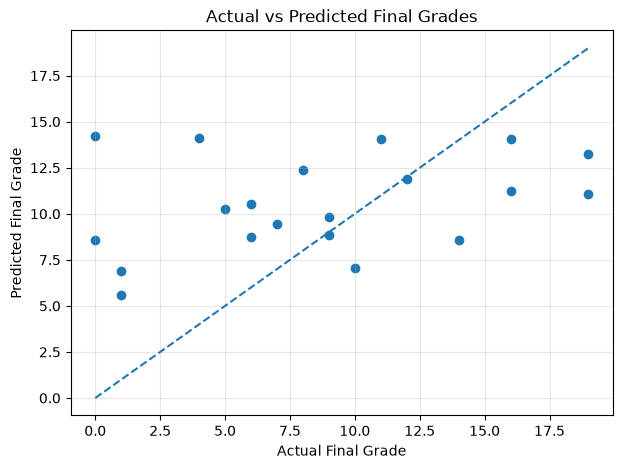

In [12]:
# Actual vs Predicted
plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred)

min_v = min(y_test.min(), y_pred.min())
max_v = max(y_test.max(), y_pred.max())
plt.plot([min_v, max_v], [min_v, max_v], linestyle="--")

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Final Grades")
plt.grid(True, alpha=0.3)
plt.show()


In [13]:
new_student = pd.DataFrame({
    "G1": [14],
    "G2": [15],
    "absences": [3],
    "age": [17],
    "Medu": [4],
    "Fedu": [3]
})

predicted_score = model.predict(new_student)[0]

print(f"Predicted final score (G3): {predicted_score:.2f} / 20")


Predicted final score (G3): 4.55 / 20
